1.Dataset Description
Isi Penjelasan:
Dataset yang digunakan berupa kumpulan berita dalam bahasa Indonesia. Dataset ini berisi teks berita yang akan diproses dari awal hingga menjadi model bahasa. Informasi dataset:

Keterangan	Isi
Nama Dataset : news_data.csv
Sumber	     : https://www.kaggle.com/datasets/ariffaizin/indonesia-election-news-berita-pemilu-2024
Jumlah Data	 : 19813baris
Jumlah Kolom : 7 Kolom
Kolom Teks	 : Content
Bahasa	Indonesia : Indonesia

Dataset yang digunakan berupa kumpulan berita dalam bahasa Indonesia. Dataset ini berisi teks berita yang akan diproses dari awal hingga menjadi model bahasa. Informasi dataset:

In [ ]:
2. Corpus Exploration

import nltk
nltk.download('punkt')
from nltk.tokenize import sent_tokenize, word_tokenize

# === HITUNG STATISTIK LENGKAP ===
kolom_teks = 'article_text'

# Pastikan teks bersih
df = df.dropna(subset=[kolom_teks])
df[kolom_teks] = df[kolom_teks].astype(str)

# Hitung per dokumen
df['jumlah_kalimat'] = df[kolom_teks].apply(lambda x: len(sent_tokenize(x)))
df['jumlah_token'] = df[kolom_teks].apply(lambda x: len(word_tokenize(x)))
df['jumlah_karakter'] = df[kolom_teks].apply(len)

# Tampilkan hasil
print("=== STATISTIK CORPUS ===")
print(f"Jumlah dokumen      : {len(df)}")
print(f"Jumlah kalimat      : {df['jumlah_kalimat'].sum()}")
print(f"Jumlah token        : {df['jumlah_token'].sum()}")
print(f"Jumlah karakter     : {df['jumlah_karakter'].sum()}")
print(f"Rata-rata kata/dok  : {df['jumlah_token'].mean():.1f}")
print(f"Dokumen terpendek   : {df['jumlah_token'].min()} token")
print(f"Dokumen terpanjang  : {df['jumlah_token'].max()} token")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


=== STATISTIK CORPUS ===
Jumlah dokumen      : 19812
Jumlah kalimat      : 422607
Jumlah token        : 7699093
Jumlah karakter     : 46415795
Rata-rata kata/dok  : 388.6
Dokumen terpendek   : 10 token
Dokumen terpanjang  : 11386 token


Penjelasan:
Dari hasil di atas, terlihat bahwa dataset terdiri dari berita dengan panjang yang bervariasi. Informasi ini penting untuk mengetahui karakteristik data sebelum diproses lebih lanjut.

In [ ]:
3. Data Cleaning
# Hapus data kosong
df = df.dropna()
print("Setelah hapus data kosong:", len(df))

# Ubah SEMUA isi kolom jadi teks biasa DULU, baru hapus duplikat
for kolom in df.columns:
    df[kolom] = df[kolom].apply(lambda x: str(x) if isinstance(x, list) else x)

# Baru hapus duplikat
df = df.drop_duplicates()
print("Setelah hapus duplikat:", len(df))

Setelah hapus data kosong: 17935
Setelah hapus duplikat: 17935


Penjelasan:
Langkah ini memastikan dataset bersih dari data yang hilang dan berulang, sehingga hasil analisis menjadi lebih akurat.

In [ ]:
4. Sentence Segmantitation
    import nltk
nltk.download('punkt')
from nltk.tokenize import sent_tokenize

teks = str(df['article_text'].iloc[0])
hasil = sent_tokenize(teks)

print("Jumlah kalimat:", len(hasil))
print("Kalimat pertama:", hasil[0])

Jumlah kalimat: 15
Kalimat pertama: Sekjen PDIP sekaligus Sekretaris Tim Pemenang Nasional (TPN) Ganjar Pranowo-Mahfud MD, Hasto Kristiyanto, ingin debat calon presiden dan calon wakil presiden saling adu gagasan.


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Penjelasan:
Sentence segmentation memisahkan satu paragraf utuh menjadi beberapa kalimat berdasarkan tanda baca akhir kalimat seperti titik, tanda seru, dan tanda tanya.

In [ ]:
5. Tokenazitaion
from nltk.tokenize import word_tokenize

# Ambil satu kalimat sebagai contoh
satu_kalimat = kalimat[0]
token = word_tokenize(satu_kalimat)

print("Kalimat asli:", satu_kalimat)
print("\nHasil Tokenisasi:")
print(token)
print(f"\nJumlah token: {len(token)}")

Kalimat asli: Hasto Ingin Debat Pilpres Pertarungan Gagasan dan Tak Ada Rekayasa

Hasil Tokenisasi:
['Hasto', 'Ingin', 'Debat', 'Pilpres', 'Pertarungan', 'Gagasan', 'dan', 'Tak', 'Ada', 'Rekayasa']

Jumlah token: 10


Penjelasan:
Tokenisasi memisahkan kalimat menjadi satuan-satuan kata atau tanda baca. Ini adalah langkah dasar agar komputer dapat memproses teks per kata.

In [ ]:
6. Normalization
import re

def normalisasi(teks):
    # Ubah jadi huruf kecil
    teks = teks.lower()
    # Hapus tanda baca dan angka
    teks = re.sub(r'[^a-zA-Z\s]', '', teks)
    # Hapus spasi berlebih
    teks = re.sub(r'\s+', ' ', teks).strip()
    return teks

# Coba
teks_awal = "Berita TERBARU hari ini, tanggal 16 Oktober!!!"
teks_akhir = normalisasi(teks_awal)

print("Sebelum:", teks_awal)
print("Sesudah:", teks_akhir)

Sebelum: Berita TERBARU hari ini, tanggal 16 Oktober!!!
Sesudah: berita terbaru hari ini tanggal oktober


Penjelasan:
Normalisasi membuat semua teks menjadi seragam — huruf kecil semua, tanpa tanda baca dan simbol yang tidak diperlukan. Hal ini agar kata yang sama tidak dianggap berbeda hanya karena huruf besar/kecil.

In [ ]:
7. Stopword Removal
from nltk.corpus import stopwords
nltk.download('stopwords')

# Ambil daftar stopword bahasa Indonesia
stopword = set(stopwords.words('indonesian'))

def hapus_stopword(daftar_kata):
    bersih = [kata for kata in daftar_kata if kata not in stopword]
    return bersih

# Coba
token_bersih = hapus_stopword(token)

print("Sebelum:", token)
print("Sesudah:", token_bersih)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Sebelum: ['Hasto', 'Ingin', 'Debat', 'Pilpres', 'Pertarungan', 'Gagasan', 'dan', 'Tak', 'Ada', 'Rekayasa']
Sesudah: ['Hasto', 'Ingin', 'Debat', 'Pilpres', 'Pertarungan', 'Gagasan', 'Tak', 'Ada', 'Rekayasa']


Penjelasan:
Stopword adalah kata-kata yang sering muncul namun tidak memiliki makna khusus seperti: yang, di, ke, dan, ini. Menghapusnya dapat mempercepat proses analisis tanpa mengubah makna utama teks secara signifikan.

In [ ]:
8. Stemming
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

factory = StemmerFactory()
stemmer = factory.create_stemmer()

def proses_stemming(daftar_kata):
    hasil = [stemmer.stem(kata) for kata in daftar_kata]
    return hasil

# Coba
token_stem = proses_stemming(token_bersih)

print("Sebelum:", token_bersih)
print("Sesudah:", token_stem)

Sebelum: ['Hasto', 'Ingin', 'Debat', 'Pilpres', 'Pertarungan', 'Gagasan', 'Tak', 'Ada', 'Rekayasa']
Sesudah: ['hasto', 'ingin', 'debat', 'pilpres', 'tarung', 'gagas', 'tak', 'ada', 'rekayasa']


Penjelasan:
Stemming mengubah kata berimbuhan menjadi kata dasarnya. Contoh: berjalan → jalan, makanan → makan. Dengan cara ini, kata yang berasal dari akar yang sama akan dihitung sebagai satu kelompok.

9. POS Tagging
Penjelasan Konsep:
POS Tagging adalah proses memberikan label kelas kata pada setiap token, misalnya:
Kata Benda → orang, rumah, jakarta
Kata Kerja → membaca, menulis, belajar
Kata Sifat → bagus, cepat, indah
Kata Penghubung → dan, tetapi, atau
Contoh hasil manual:
Saya/Pron belajar/KataKerja NLP/KataBenda hari ini/KeteranganWaktu
Fungsi: Membantu komputer memahami peran setiap kata dalam struktur kalimat.

10. Dependency Parsing
Penjelasan Konsep:
Dependency Parsing menunjukkan hubungan antar kata dalam kalimat, yaitu:
Kata mana yang menjadi inti kalimat
Kata mana yang menjelaskan kata lain
Hubungan: subjek → predikat → objek
Contoh:
"Mahasiswa membaca buku"
  ↓        ↓     ↓
Subjek    Inti  Objek
Fungsi: Memahami struktur dan makna kalimat secara mendalam, tidak hanya sekadar daftar kata.

In [ ]:
11. N-gram
from nltk.util import bigrams, trigrams
from collections import Counter

# Gabungkan semua teks yang sudah diproses
semua_teks = " ".join(df.iloc[:, 0].astype(str).apply(normalisasi))
semua_token = semua_teks.split()

# Unigram
unigram = Counter(semua_token)
print("=== 10 Kata Paling Sering Muncul ===")
for kata, jumlah in unigram.most_common(10):
    print(f"{kata:<15} : {jumlah} kali")

# Bigram
bigram_list = list(bigrams(semua_token))
bigram_count = Counter(bigram_list)
print("\n=== 10 Bigram Paling Sering Muncul ===")
for pasangan, jumlah in bigram_count.most_common(10):
    print(f"{pasangan[0]} {pasangan[1]:<20} : {jumlah} kali")

# Trigram
trigram_list = list(trigrams(semua_token))
trigram_count = Counter(trigram_list)
print("\n=== 10 Trigram Paling Sering Muncul ===")
for tiga, jumlah in trigram_count.most_common(10):
    print(f"{tiga[0]} {tiga[1]} {tiga[2]:<25} : {jumlah} kali")

=== 10 Kata Paling Sering Muncul ===
di              : 4738 kali
ganjar          : 2804 kali
prabowo         : 2692 kali
anies           : 2296 kali
soal            : 2188 kali
ke              : 1799 kali
cawapres        : 1750 kali
jadi            : 1642 kali
dan             : 1626 kali
gibran          : 1622 kali

=== 10 Bigram Paling Sering Muncul ===
cak imin                 : 989 kali
jadi cawapres             : 538 kali
cawapres ganjar               : 357 kali
cawapres prabowo              : 339 kali
aniescak imin                 : 333 kali
di pilpres              : 327 kali
dukung prabowo              : 308 kali
cawapres anies                : 238 kali
mahfud md                   : 225 kali
dukung ganjar               : 214 kali

=== 10 Trigram Paling Sering Muncul ===
jadi cawapres ganjar                    : 149 kali
jadi cawapres prabowo                   : 148 kali
gibran jadi cawapres                  : 104 kali
batas usia caprescawapres            : 67 kali
jadi cawapres a

Penjelasan:
Unigram melihat seberapa sering tiap kata muncul sendirian
Bigram melihat pasangan kata yang sering muncul berurutan
Trigram melihat tiga kata yang sering muncul berurutan
Semakin besar N, semakin kontekstual tetapi semakin sedikit yang muncul

In [ ]:
12.Language Model
total_token = sum(unigram.values())

# Probabilitas Unigram
def prob_unigram(kata):
    return unigram.get(kata, 0) / total_token

# Probabilitas Bigram
def prob_bigram(kata1, kata2):
    pembilang = bigram_count.get((kata1, kata2), 0)
    penyebut = unigram.get(kata1, 0)
    if penyebut == 0:
        return 0.0
    return pembilang / penyebut

# Laplace Smoothing
jumlah_vocab = len(unigram)
def prob_bigram_smooth(kata1, kata2):
    pembilang = bigram_count.get((kata1, kata2), 0) + 1
    penyebut = unigram.get(kata1, 0) + jumlah_vocab
    return pembilang / penyebut

# Uji beberapa kalimat
uji_kalimat = [
    "berita terbaru hari ini",
    "presiden memberikan sambutan"
]

for k in uji_kalimat:
    kata = k.lower().split()
    p = 1.0
    for i in range(len(kata)-1):
        p *= prob_bigram_smooth(kata[i], kata[i+1])
    print(f"P('{k}') = {p:.8f}")

P('berita terbaru hari ini') = 0.00000000
P('presiden memberikan sambutan') = 0.00000001


Penjelasan:
Language model menghitung seberapa mungkin sebuah urutan kata muncul. Semakin tinggi nilainya, semakin wajar kalimat tersebut menurut model. Laplace smoothing memastikan tidak ada probabilitas yang bernilai nol.

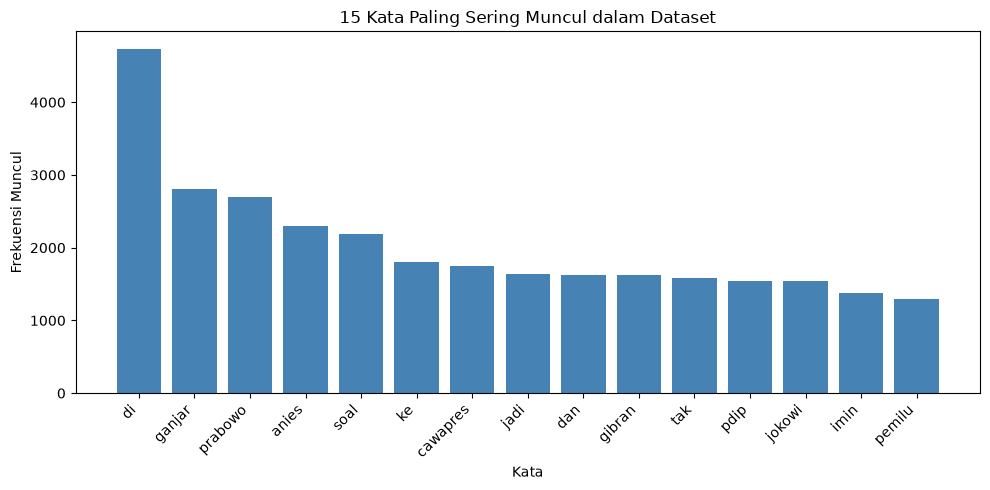

In [ ]:
13. Visualisasi
import matplotlib.pyplot as plt

# Top 15 kata
top15 = unigram.most_common(15)
kata_nama = [item[0] for item in top15]
kata_jumlah = [item[1] for item in top15]

plt.figure(figsize=(10, 5))
plt.bar(kata_nama, kata_jumlah, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Kata")
plt.ylabel("Frekuensi Muncul")
plt.title("15 Kata Paling Sering Muncul dalam Dataset")
plt.tight_layout()
plt.show()

Penjelasan:
Grafik membantu kita melihat pola data dengan lebih mudah — kata apa yang paling dominan, sebaran panjang teks, dan lainnya.

14. Analysis
Berdasarkan seluruh proses yang telah dilakukan, dapat diamati bahwa:
Dataset berita didominasi oleh kata-kata umum yang berkaitan dengan topik berita
Setelah preprocessing, jumlah kata berkurang karena penghapusan stopword dan stemming
Semakin besar nilai n-gram, semakin sedikit kombinasi yang ditemukan dalam data
Masalah utama yang ditemukan adalah banyaknya kombinasi kata yang belum pernah muncul dalam data, sehingga diperlukan teknik smoothing

15. Conclusion
Pemrosesan teks adalah langkah penting agar komputer dapat memahami bahasa manusia. Proses ini dimulai dari membaca data, membersihkan, memisahkan kalimat, memisahkan kata, menyeragamkan bentuk, menghapus kata yang tidak perlu, hingga mengubah ke bentuk dasar. Hasil akhirnya dapat digunakan untuk membangun model bahasa sederhana yang mampu menghitung probabilitas urutan kata. Setiap langkah saling berkaitan dan sangat mempengaruhi kualitas hasil akhir.


Format Dataset Description
Mahasiswa Wajib Menjelaskan
Keterangan	Isi
Nama Dataset : news_data.csv
Sumber	     : https://www.kaggle.com/datasets/ariffaizin/indonesia-election-news-berita-pemilu-2024
Jumlah Data	 : 19813baris
Jumlah Kolom : 7 Kolom
Kolom Teks	 : Content
Kolom Label  : Tidak ada label khusus
Bahasa	Indonesia : Indonesia
Jenis Data : Teks berita

In [ ]:
Stastik yang harus di tampilkan
import nltk
nltk.download('punkt')
from nltk.tokenize import sent_tokenize, word_tokenize

# === HITUNG STATISTIK LENGKAP ===
kolom_teks = 'article_text'

# Pastikan teks bersih
df = df.dropna(subset=[kolom_teks])
df[kolom_teks] = df[kolom_teks].astype(str)

# Hitung per dokumen
df['jumlah_kalimat'] = df[kolom_teks].apply(lambda x: len(sent_tokenize(x)))
df['jumlah_token'] = df[kolom_teks].apply(lambda x: len(word_tokenize(x)))
df['jumlah_karakter'] = df[kolom_teks].apply(len)

# Tampilkan hasil
print("=== STATISTIK CORPUS ===")
print(f"Jumlah dokumen      : {len(df)}")
print(f"Jumlah kalimat      : {df['jumlah_kalimat'].sum()}")
print(f"Jumlah token        : {df['jumlah_token'].sum()}")
print(f"Jumlah karakter     : {df['jumlah_karakter'].sum()}")
print(f"Rata-rata kata/dok  : {df['jumlah_token'].mean():.1f}")
print(f"Dokumen terpendek   : {df['jumlah_token'].min()} token")
print(f"Dokumen terpanjang  : {df['jumlah_token'].max()} token")


penjelasan : Kode ini berfungsi untuk menghitung seberapa besar dataset beritamu — mulai dari jumlah berita, total kalimat, total kata, sampai berapa rata-rata panjang setiap berita. Hasilnya dipakai untuk memahami karakteristik data sebelum diproses lebih lanjut

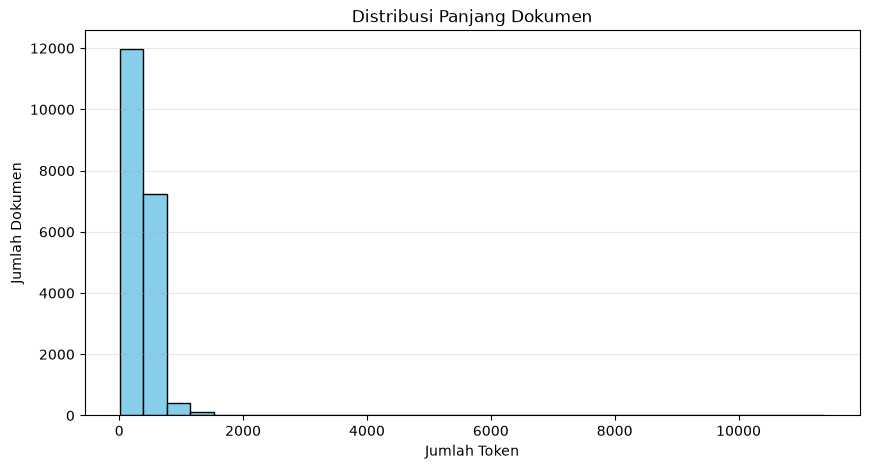

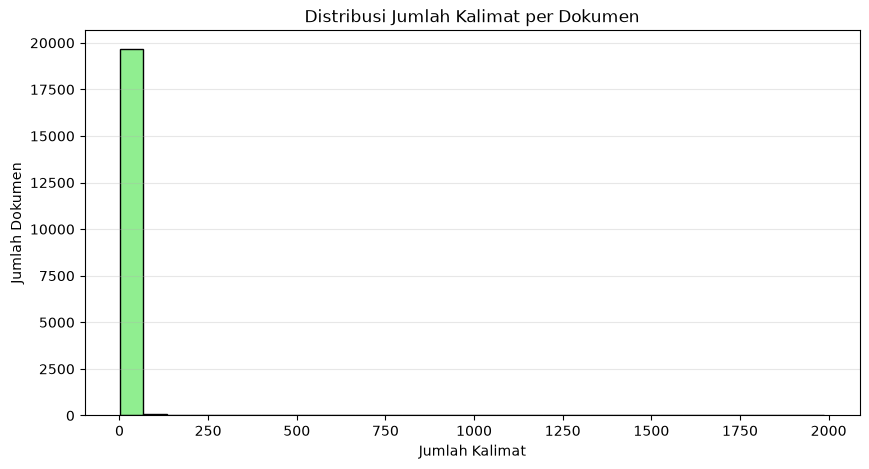

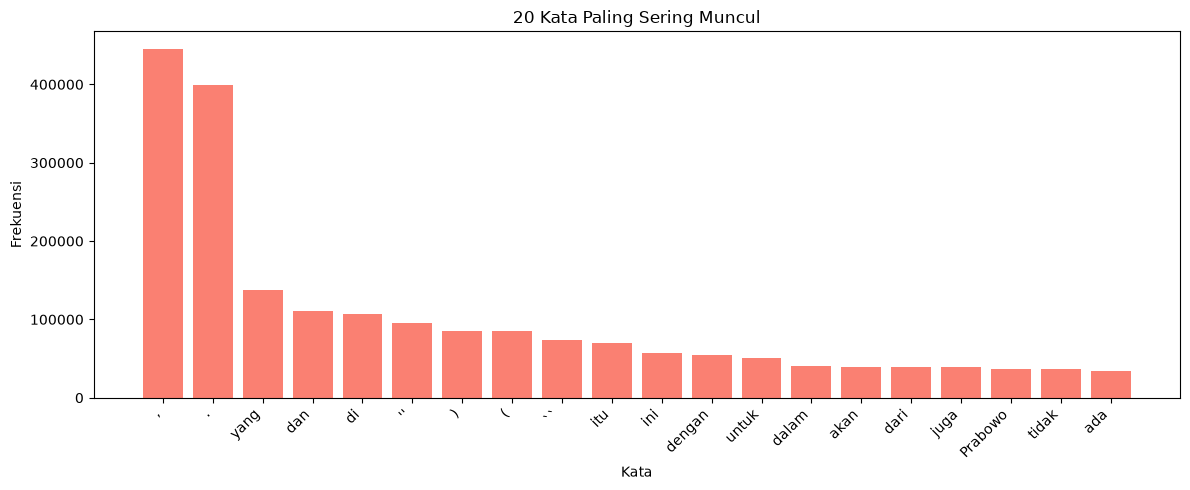

In [ ]:
Visualisasi Yang harus di buat (minimal 3)
import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import word_tokenize, sent_tokenize

kolom_teks = 'article_text'

# Hitung dulu
df['jumlah_kalimat'] = df[kolom_teks].apply(lambda x: len(sent_tokenize(str(x))))

# GRAFIK 1 — Distribusi Panjang Dokumen
plt.figure(figsize=(10, 5))
plt.hist(df['jumlah_token'], bins=30, color='skyblue', edgecolor='black')
plt.xlabel('Jumlah Token')
plt.ylabel('Jumlah Dokumen')
plt.title('Distribusi Panjang Dokumen')
plt.grid(axis='y', alpha=0.3)
plt.show()

# GRAFIK 2 — Distribusi Jumlah Kalimat
plt.figure(figsize=(10, 5))
plt.hist(df['jumlah_kalimat'], bins=30, color='lightgreen', edgecolor='black')
plt.xlabel('Jumlah Kalimat')
plt.ylabel('Jumlah Dokumen')
plt.title('Distribusi Jumlah Kalimat per Dokumen')
plt.grid(axis='y', alpha=0.3)
plt.show()

# GRAFIK 3 — Top 20 Kata
semua_teks = " ".join(df[kolom_teks].astype(str))
semua_token = word_tokenize(semua_teks)
top_unigram = Counter(semua_token).most_common(20)

kata_nama = [item[0] for item in top_unigram]
kata_jumlah = [item[1] for item in top_unigram]

plt.figure(figsize=(12, 5))
plt.bar(kata_nama, kata_jumlah, color='salmon')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Kata')
plt.ylabel('Frekuensi')
plt.title('20 Kata Paling Sering Muncul')
plt.tight_layout()
plt.show()


Penjelasan : 
Grafik 1: Distribusi Panjang Dokumen
Grafik ini menunjukkan seberapa panjang setiap berita di dataset, dihitung berdasarkan jumlah kata/token. Sumbu bawah = jumlah kata, sumbu kiri = jumlah berita yang memiliki panjang tersebut.
Artinya: Sebagian besar berita di dataset ini tergolong pendek hingga sedang — paling banyak berisi sekitar 0–500 kata. Sangat sedikit berita yang sangat panjang (di atas 1.000 kata). Ini wajar untuk berita media umum.
Grafik 2: Distribusi Jumlah Kalimat per Dokumen
Grafik ini menunjukkan berapa kalimat yang ada di setiap berita.
Artinya: Polanya mirip dengan grafik pertama — sebagian besar berita terdiri dari sedikit kalimat. Hampir semua berita memiliki kurang dari 250 kalimat. Ini konsisten dengan grafik panjang kata: berita yang pendek pasti juga memiliki kalimat yang tidak banyak.
Grafik 3: 20 Kata Paling Sering Muncul
Grafik ini menampilkan 20 kata yang paling banyak muncul di seluruh dataset, diurutkan dari yang tertinggi. Sumbu bawah = nama kata, sumbu kiri = berapa kali muncul.
Artinya: Kata yang paling dominan adalah tanda baca dan kata hubung umum seperti "yang", "dan", "di". Semakin ke kanan, frekuensinya makin menurun. Nama tokoh seperti "Prabowo" juga terlihat masuk ke dalam 20 kata teratas, yang menegaskan topik utama dataset ini adalah berita Pemilu 2024.
Ketiga grafik ini saling melengkapi: dua grafik pertama memberi tahu seberapa panjang dan singkat isi beritanya, sedangkan grafik ketiga memberi tahu apa saja yang paling sering dibicarakan di dalamnya. Hasilnya menunjukkan dataset ini terdiri dari berita-berita pendek-sedang dengan topik utama seputar Pemilu 2024

In [39]:
from nltk.util import bigrams, trigrams
from collections import Counter
from nltk.tokenize import word_tokenize

# Ambil semua teks
semua_teks = " ".join(df['article_text'].astype(str))
semua_token = word_tokenize(semua_teks)

# ======================================
# TOP 20 UNIGRAM
# ======================================
print("=" * 50)
print("TOP 20 UNIGRAM")
print("=" * 50)
unigram_count = Counter(semua_token)
top_unigram = unigram_count.most_common(20)
for kata, jumlah in top_unigram:
    print(f"{kata:<15} : {jumlah} kali")

# ======================================
# TOP 20 BIGRAM
# ======================================
print("\n" + "=" * 50)
print("TOP 20 BIGRAM")
print("=" * 50)
bigram_list = list(bigrams(semua_token))
bigram_count = Counter(bigram_list)
top_bigram = bigram_count.most_common(20)
for pasangan, jumlah in top_bigram:
    print(f"{pasangan[0]} {pasangan[1]:<20} : {jumlah} kali")

# ======================================
# TOP 20 TRIGRAM
# ======================================
print("\n" + "=" * 50)
print("TOP 20 TRIGRAM")
print("=" * 50)
trigram_list = list(trigrams(semua_token))
trigram_count = Counter(trigram_list)
top_trigram = trigram_count.most_common(20)
for tiga, jumlah in top_trigram:
    print(f"{tiga[0]} {tiga[1]} {tiga[2]:<25} : {jumlah} kali")

TOP 20 UNIGRAM
,               : 411794 kali
.               : 369948 kali
yang            : 127982 kali
dan             : 103596 kali
di              : 99803 kali
''              : 87791 kali
)               : 79352 kali
(               : 79193 kali
``              : 68286 kali
itu             : 64494 kali
ini             : 52093 kali
dengan          : 50269 kali
untuk           : 47676 kali
dalam           : 37374 kali
dari            : 37007 kali
akan            : 36610 kali
juga            : 36387 kali
tidak           : 34037 kali
Prabowo         : 33453 kali
ada             : 31966 kali

TOP 20 BIGRAM
, ''                   : 74566 kali
. ``                   : 66383 kali
) .                    : 29414 kali
'' kata                 : 23163 kali
ADVERTISEMENT SCROLL               : 17854 kali
SCROLL TO                   : 17854 kali
TO CONTINUE             : 17854 kali
CONTINUE WITH                 : 17854 kali
WITH CONTENT              : 17854 kali
. ADVERTISEMENT        : 17571 ka

Penjelasan : Unigram adalah satu kata tunggal. Hasil ini menunjukkan daftar kata yang paling sering muncul di seluruh dataset berita, diurutkan dari frekuensi tertinggi ke terendah. Angka di belakang menunjukkan berapa kali kata tersebut muncul.
Hasil ini berguna untuk memahami isi dataset secara cepat: kita langsung tahu topik utamanya, siapa yang paling sering dibahas, dan bagian mana dari teks yang masih perlu dibersihkan sebelum dipakai untuk analisis lebih lanjut. Semakin spesifik kata yang muncul di urutan teratas, semakin jelas topik dari dataset tersebut.